# TA-07 – Redistribusi Sepeda Antarstasiun Bike Sharing dengan Q-Learning

**Mata praktikum:** Pembelajaran Mesin · **Modul 07** – Reinforcement Learning

> Catatan data: `sampleSubmission.csv` hanya berisi `datetime` dan `count` (semua 0). Kolom `datetime` dipakai sebagai **kalender simulasi** (hari kerja / akhir pekan); permintaan sepeda dibangkitkan oleh simulator (Poisson).

Jika memakai Google Colab, unggah `bike_env.py`, `qlearning.py`, dan folder `data/` terlebih dahulu.

## Langkah 1 – Persiapan lingkungan (S, A, R)

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from bike_env import *
from qlearning import *

cal = load_day_types('data/sampleSubmission.csv')
print(cal.head()); print('Hari kerja:', (cal.daytype==0).sum(), '| Akhir pekan:', (cal.daytype==1).sum())
print('Jumlah state:', N_STATES, '| Jumlah aksi:', N_ACTIONS, '| Aksi:', ACTION_NAMES)

        date  daytype
0 2011-01-20        0
1 2011-01-21        0
2 2011-01-22        1
3 2011-01-23        1
4 2011-01-24        0
Hari kerja: 197 | Akhir pekan: 78
Jumlah state: 270 | Jumlah aksi: 7 | Aksi: ['Diam', 'R->K', 'R->C', 'K->R', 'K->C', 'C->R', 'C->K']


In [2]:
# Uji lingkungan: step(action) -> new_state, reward, done
env = BikeShareEnv(seed=1); s = env.reset(daytype=0, init_stock=[10,10,10])
for a in [0, 3, 5]:
    s2, r, done, info = env.step(a); print(f'aksi={ACTION_NAMES[a]:6s} state={s2:3d} reward={r:6.1f} stok={env.stock} done={done} {info}')

aksi=Diam   state= 13 reward=   1.0 stok=[11  9 10] done=False {'served': 1, 'lost': 0, 'overflow': 0, 'moved': 0}
aksi=K->R   state= 19 reward=  -1.0 stok=[16  4 10] done=False {'served': 0, 'lost': 0, 'overflow': 0, 'moved': 5}
aksi=C->R   state= 18 reward=   1.0 stok=[20  4  6] done=False {'served': 2, 'lost': 0, 'overflow': 0, 'moved': 4}


## Langkah 2 – Implementasi Q-Learning (ε-greedy, decay stabil)

$Q(s,a)\leftarrow(1-\alpha)Q(s,a)+\alpha\,[r+\gamma\max_{a'}Q(s',a')]$ — pada langkah terminal target = $r$ (tanpa bootstrap).

In [3]:
import inspect; print(inspect.getsource(train))

def train(day_types, alpha=0.1, gamma=0.9, episodes=20000, eps_start=1.0, eps_min=0.01,
          decay_rate=0.0005, seed=42, log_every=0):
    """day_types: array tipe_hari (0/1) yang di-sample untuk tiap episode (berasal dari CSV)."""
    env = BikeShareEnv(seed)
    rng = np.random.default_rng(seed + 1)
    q = np.zeros((N_STATES, N_ACTIONS))
    visits = np.zeros((N_STATES, N_ACTIONS), dtype=int)
    rewards, lost_ep, eps_hist = [], [], []
    for ep in range(episodes):
        epsilon = eps_min + (eps_start - eps_min) * np.exp(-decay_rate * ep)
        s = env.reset(daytype=rng.choice(day_types))
        total, lost, done = 0.0, 0, False
        while not done:
            if rng.random() < epsilon:                      # eksplorasi
                a = int(rng.integers(N_ACTIONS))
            else:                                           # eksploitasi
                row = q[s]; a = int(rng.choice(np.flatnonzero(row == row.max())))
            s2, r, done, info = env.step(a)
   

In [4]:
day_types = cal['daytype'].values
q, rewards, lost, eps, visits = train(day_types, alpha=0.1, gamma=0.9, episodes=20000, decay_rate=0.0005, seed=42, log_every=4000)

ep   4000  eps=0.144  MA100 reward=   85.58


ep   8000  eps=0.028  MA100 reward=  102.12


ep  12000  eps=0.012  MA100 reward=  104.47


ep  16000  eps=0.010  MA100 reward=  110.41


ep  20000  eps=0.010  MA100 reward=  106.10


## Langkah 3 – Kurva pembelajaran

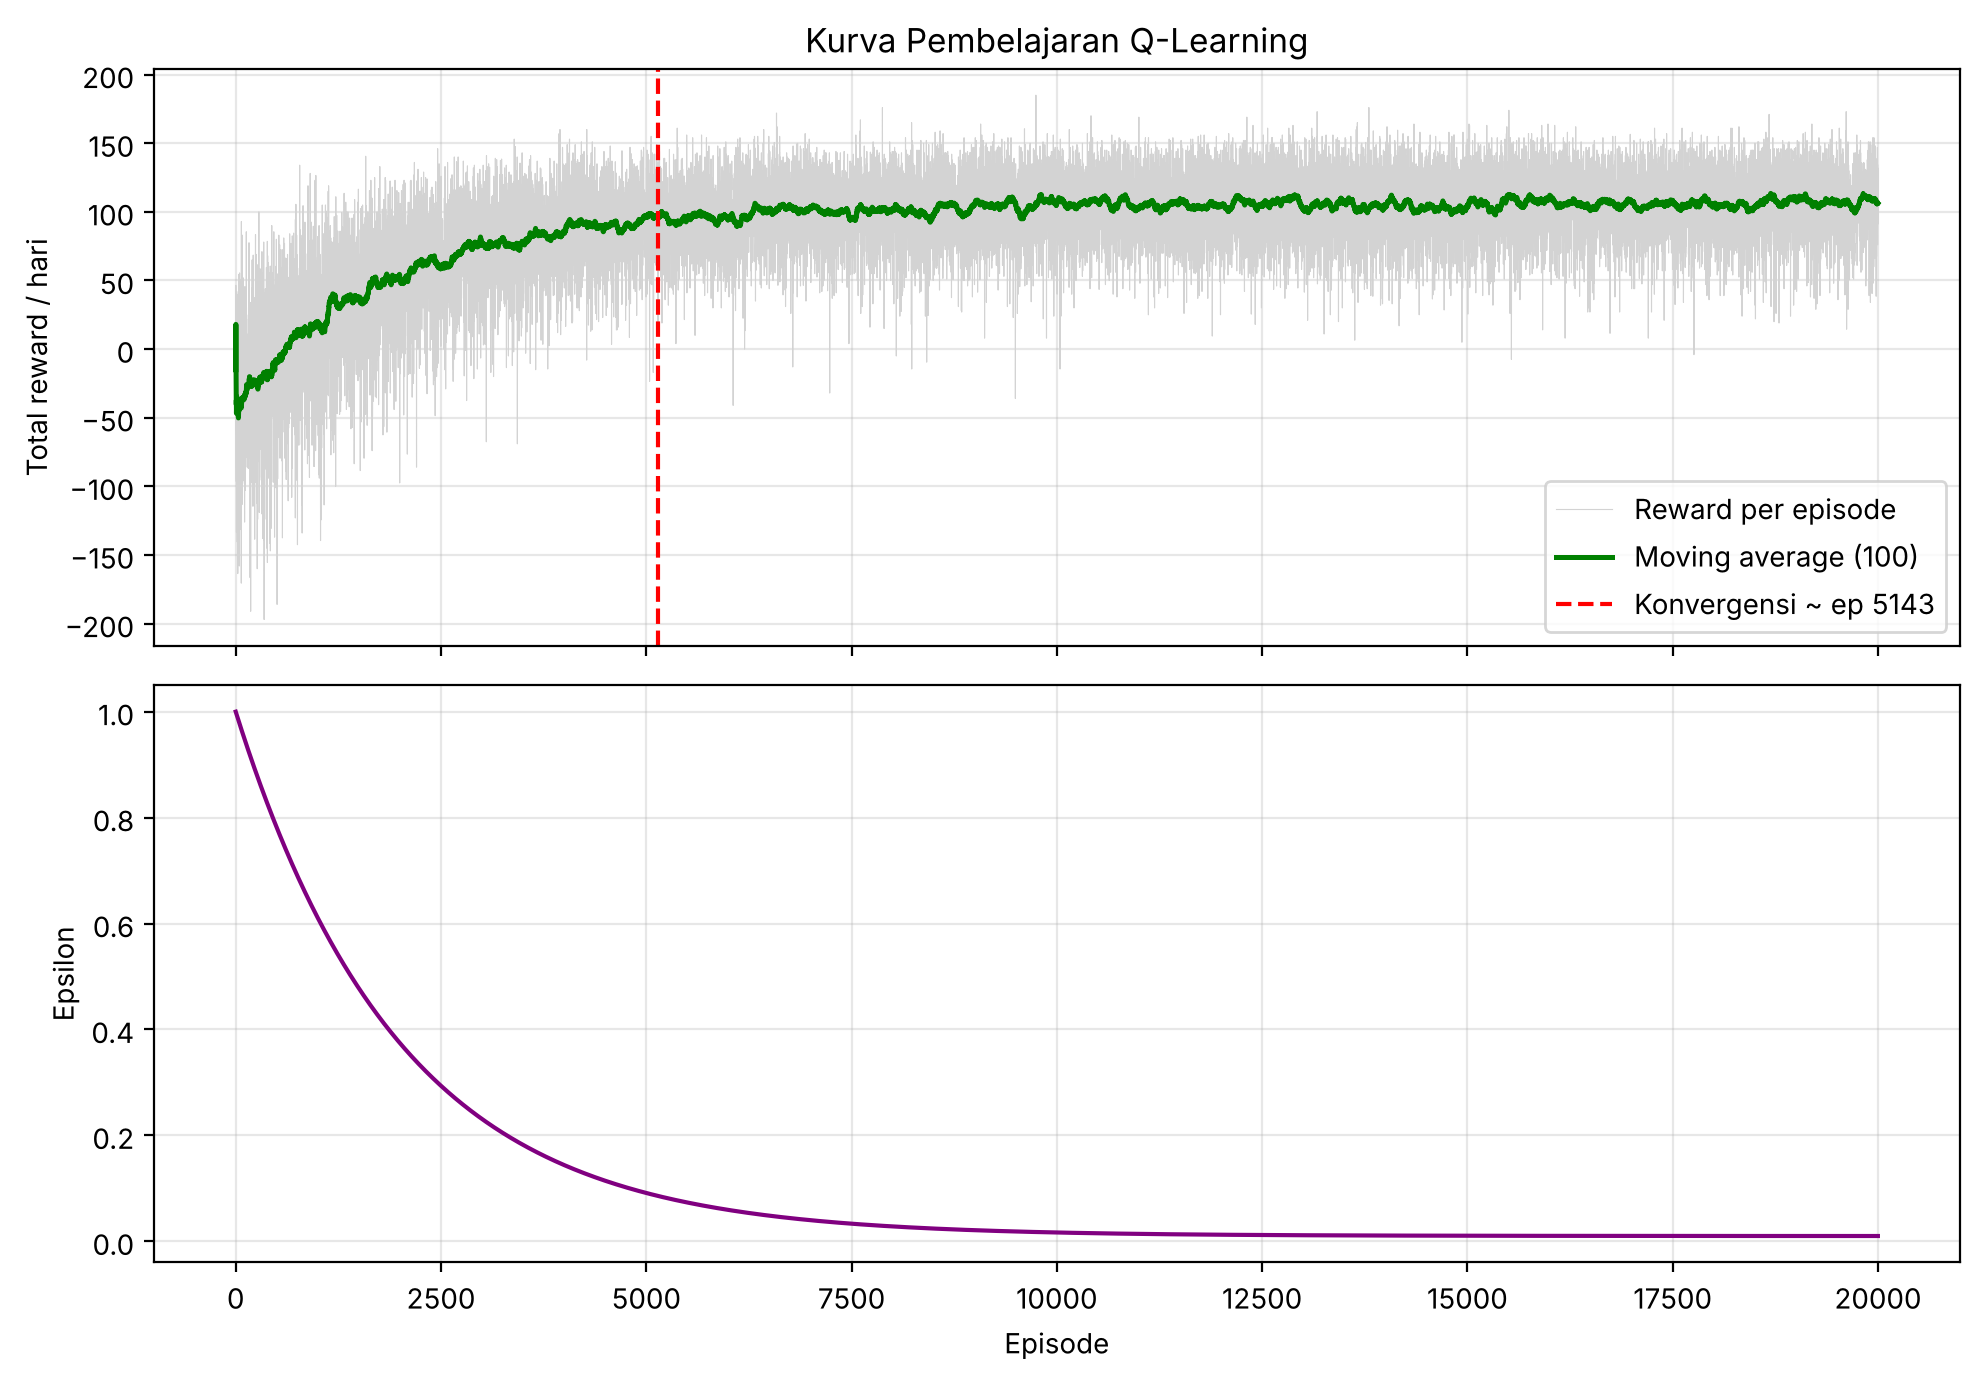

Konvergensi ~ episode 5143; plateau reward = 107.1; reward 100 episode pertama = -35.0


In [5]:
W=100; ma = pd.Series(rewards).rolling(W, min_periods=1).mean()
conv, plateau = convergence_episode(rewards, W)
fig, ax = plt.subplots(2,1,figsize=(10,7),sharex=True)
ax[0].plot(rewards,color='lightgray',lw=.4,label='Reward per episode'); ax[0].plot(ma,color='green',lw=1.8,label='Moving average (100)')
ax[0].axvline(conv,color='red',ls='--',label=f'Konvergensi ~ ep {conv}'); ax[0].legend(); ax[0].grid(alpha=.3); ax[0].set_ylabel('Total reward / hari')
ax[0].set_title('Kurva Pembelajaran Q-Learning'); ax[1].plot(eps,color='purple'); ax[1].set_ylabel('Epsilon'); ax[1].set_xlabel('Episode'); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show(); print(f'Konvergensi ~ episode {conv}; plateau reward = {plateau:.1f}; reward 100 episode pertama = {np.mean(rewards[:100]):.1f}')

**Analisis:** fluktuasi di awal terjadi karena ε≈1 (aksi hampir acak, truk memindahkan sepeda tanpa arah sehingga banyak stock-out/overflow) dan Q-Table masih nol. Setelah ε turun (< 0.1 pada episode ≈ 5.000) reward rata-rata mendatar di sekitar +107 per hari.

## Langkah 4 – Ekstrak & interpretasi kebijakan

In [6]:
policy_idx = q.argmax(1)
env = BikeShareEnv(999); rng = np.random.default_rng(999)
act_hour = np.zeros((24, N_ACTIONS))
for _ in range(1000):
    st = env.reset(daytype=0); dn=False; h=0
    while not dn:
        a = int(policy_idx[st]); act_hour[h,a]+=1; st,_,dn,_ = env.step(a); h+=1
pd.DataFrame(act_hour/act_hour.sum(1,keepdims=True), columns=ACTION_NAMES).round(2)

,Diam,R->K,R->C,K->R,K->C,C->R,C->K
0,0.15,0.26,0.00,0.03,0.02,0.40,0.14
1,0.46,0.14,0.00,0.07,0.01,0.26,0.08
2,0.61,0.07,0.00,0.04,0.02,0.23,0.01
3,0.77,0.02,0.00,0.07,0.01,0.12,0.01
4,0.89,0.01,0.00,0.04,0.01,0.03,0.01
5,0.92,0.01,0.00,0.02,0.01,0.02,0.02
6,0.02,0.00,0.00,0.03,0.93,0.02,0.00
7,0.03,0.00,0.00,0.56,0.15,0.19,0.07
8,0.03,0.01,0.00,0.55,0.14,0.18,0.10
9,0.03,0.00,0.00,0.60,0.09,0.18,0.08


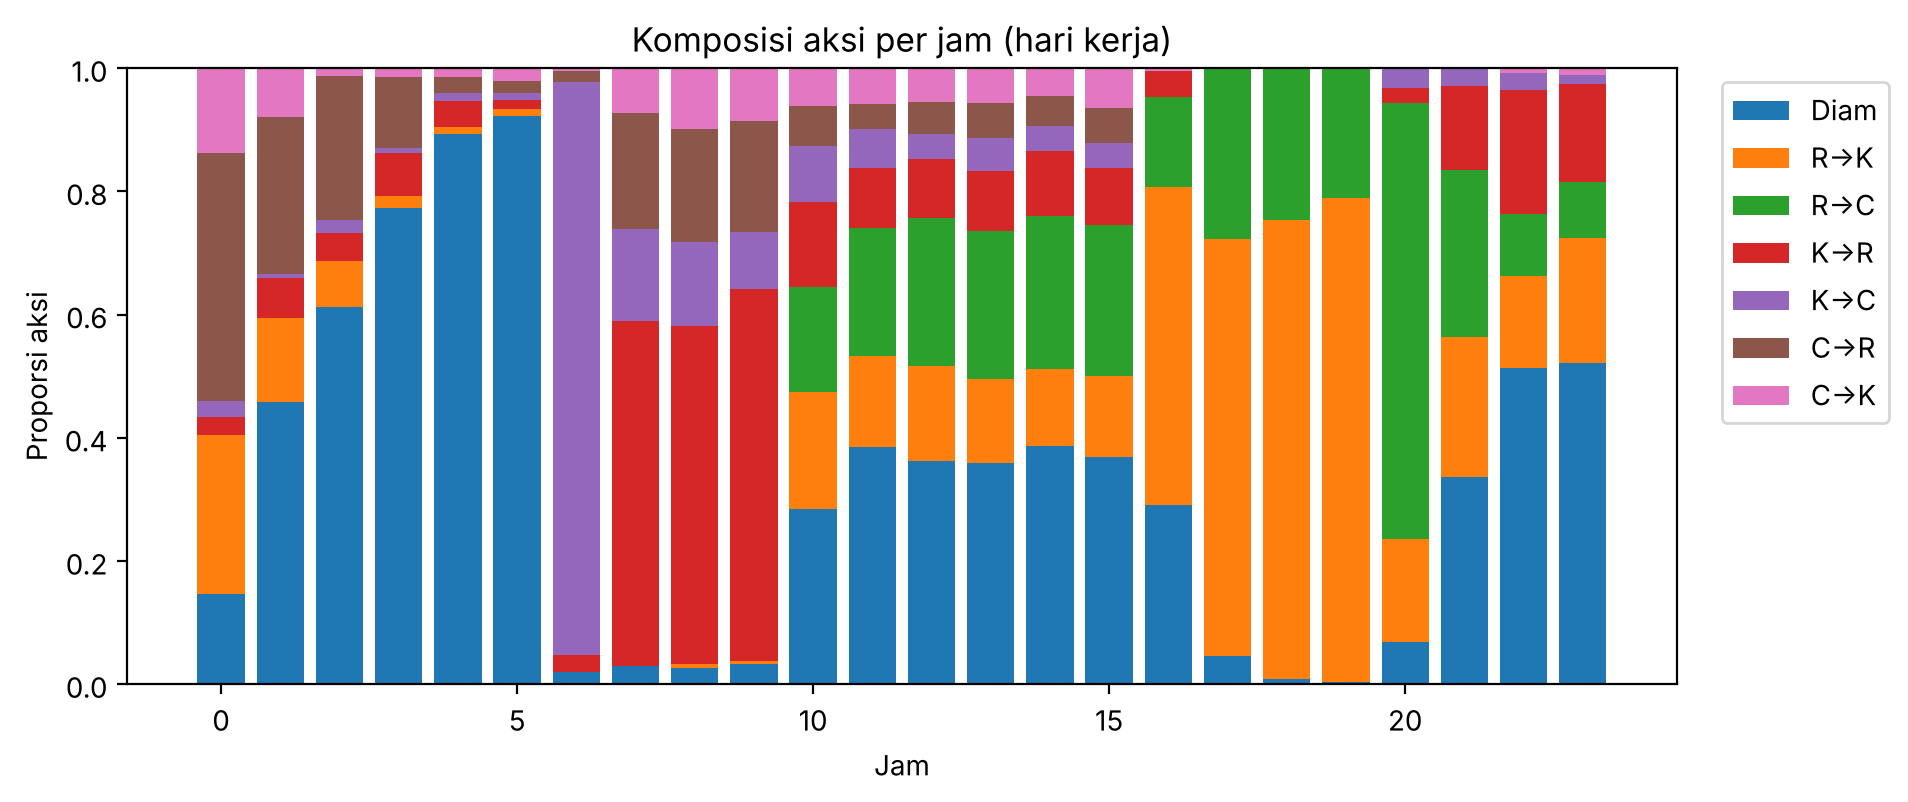

In [7]:
frac = act_hour/act_hour.sum(1,keepdims=True); bottom=np.zeros(24); plt.figure(figsize=(10,4))
for a in range(N_ACTIONS): plt.bar(range(24), frac[:,a], bottom=bottom, color=plt.get_cmap('tab10')(a), label=ACTION_NAMES[a]); bottom+=frac[:,a]
plt.legend(bbox_to_anchor=(1.02,1),loc='upper left'); plt.xlabel('Jam'); plt.ylabel('Proporsi aksi'); plt.title('Komposisi aksi per jam (hari kerja)'); plt.show()

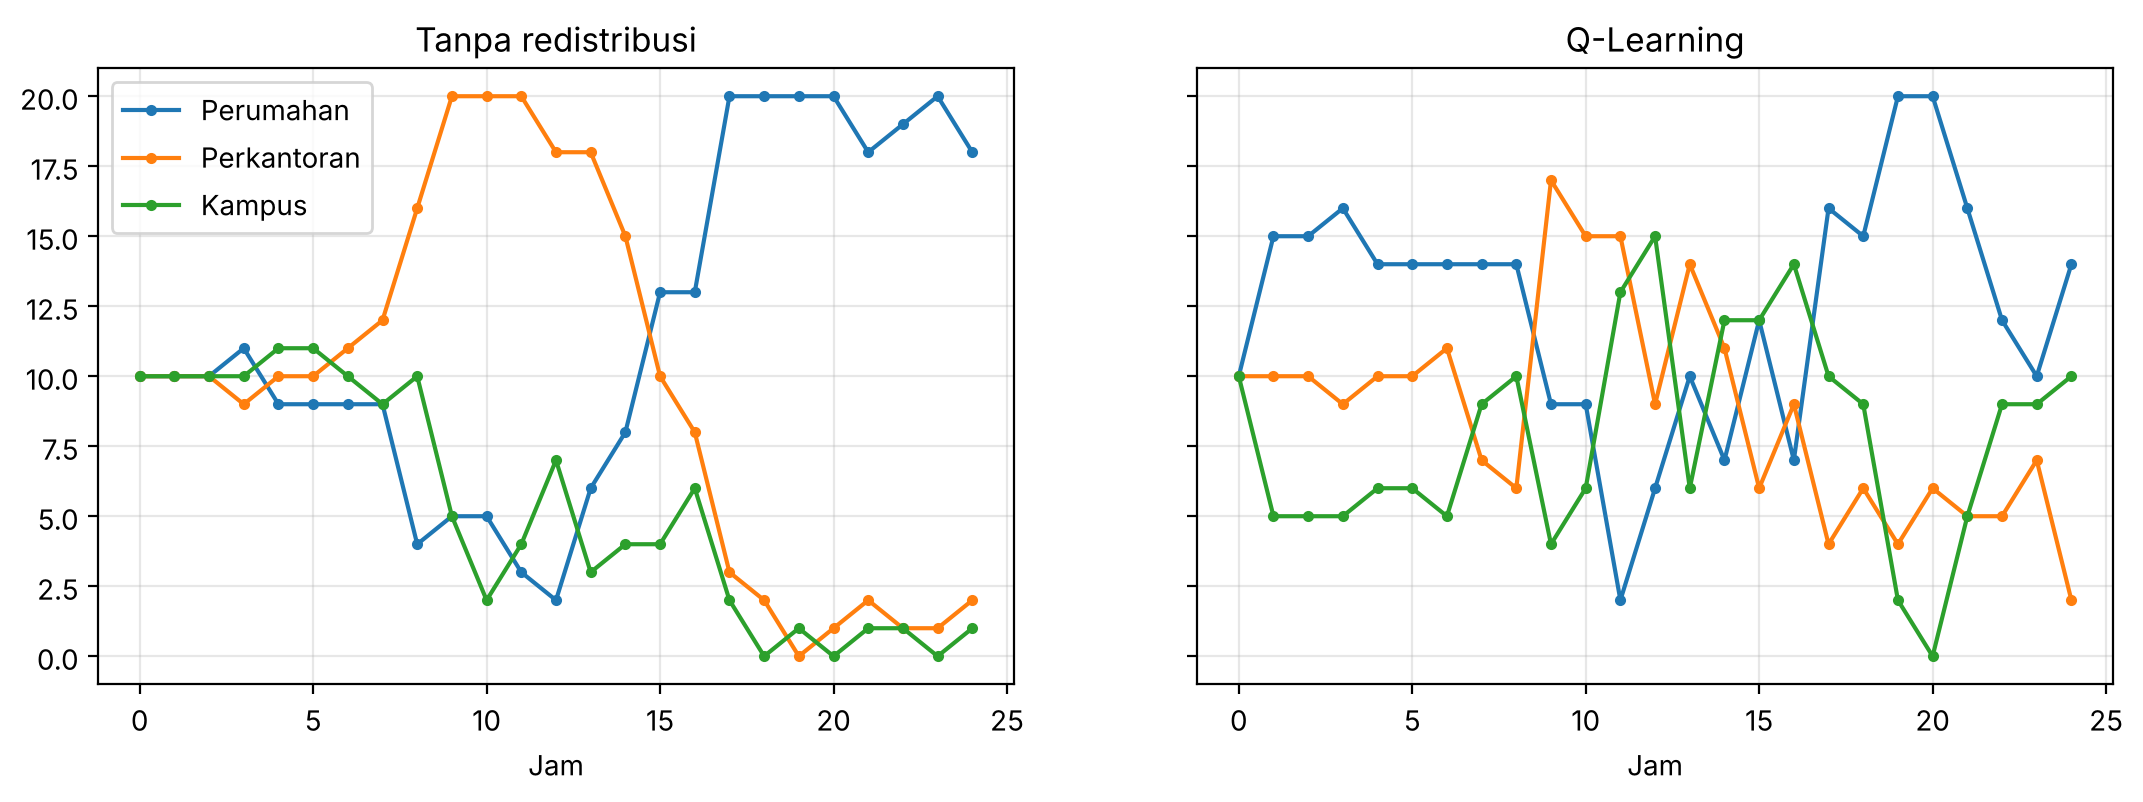

In [8]:
def trace(policy, seed=5):
    e = BikeShareEnv(seed); s = e.reset(daytype=0, init_stock=[10,10,10]); H=[e.stock.copy()]; d=False
    while not d: s,_,d,_ = e.step(policy(s,e)); H.append(e.stock.copy())
    return np.array(H)
fig,ax = plt.subplots(1,2,figsize=(13,4),sharey=True)
for a,(t,p) in zip(ax,[('Tanpa redistribusi',no_move_policy),('Q-Learning',q_policy(q))]):
    H=trace(p); [a.plot(H[:,i],marker='o',ms=3,label=n) for i,n in enumerate(STATIONS)]; a.set_title(t); a.set_xlabel('Jam'); a.grid(alpha=.3)
ax[0].legend(); plt.show()

In [9]:
res = {'Q-Learning': evaluate(q_policy(q)), 'Tanpa redistribusi': evaluate(no_move_policy),
       'Heuristik (selisih>=8)': evaluate(heuristic_policy), 'Acak': evaluate(random_policy_factory(7))}
pd.DataFrame(res).T.round(2)

,reward,served,lost,overflow,moves,service_level_%
Q-Learning,107.91,139.88,4.01,2.60,14.62,97.21
Tanpa redistribusi,4.20,112.94,31.00,7.87,0.00,78.46
Heuristik (selisih>=8),99.62,136.97,6.91,3.68,9.25,95.20
Acak,-26.20,109.72,33.60,6.67,18.19,76.56


## Langkah 5 – Eksperimen hiperparameter (γ: default 0.9 vs sangat rendah 0.1)

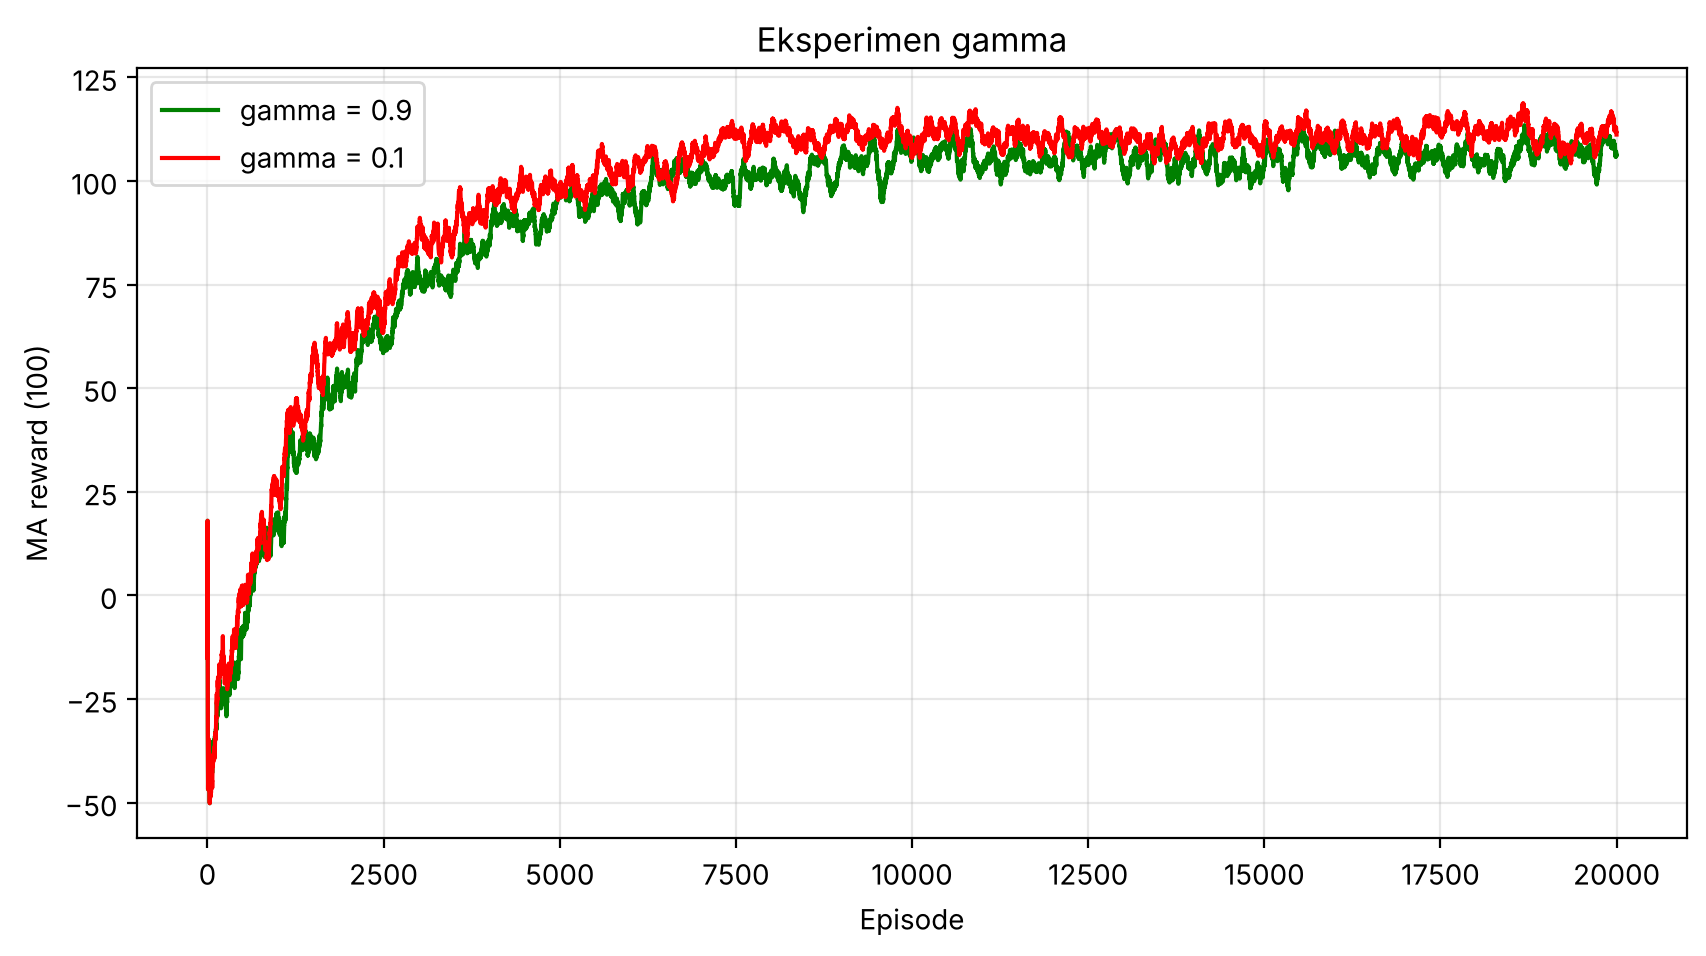

,gamma,reward_eval,service,lost,moves
0,0.9,107.91,97.21,4.01,14.62
1,0.1,111.49,97.21,4.02,10.56


In [10]:
fig = plt.figure(figsize=(10,5)); rows=[]
for g,col in [(0.9,'green'),(0.1,'red')]:
    q_g, r_g, *_ = train(day_types, alpha=0.1, gamma=g, episodes=20000, seed=42)
    plt.plot(pd.Series(r_g).rolling(100,min_periods=1).mean(), color=col, label=f'gamma = {g}')
    ev = evaluate(q_policy(q_g)); rows.append(dict(gamma=g, reward_eval=ev['reward'], service=ev['service_level_%'], lost=ev['lost'], moves=ev['moves']))
plt.legend(); plt.grid(alpha=.3); plt.xlabel('Episode'); plt.ylabel('MA reward (100)'); plt.title('Eksperimen gamma'); plt.show()
pd.DataFrame(rows).round(2)

**Catatan:** untuk kesimpulan yang kokoh, jalankan `run_multiseed.py` (5 seed). Pada lingkungan ini γ rendah ternyata **tidak** merugikan – lihat pembahasan di laporan.